# EMQA_L4_brent_im

**Margins are procyclical: the Brent initial margin in 2026**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_brent_im/EMQA_L4_brent_im.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# ICE Brent front-month futures (continuous series, rolls on the first trading day of each month), USD/bbl
F = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')['brent_usd_bbl'].dropna()
END = pd.Timestamp('2026-10-31')
F = F[:END]
print('Brent', d(F.index[0]), 'to', d(F.index[-1]), len(F), 'trading days')

Brent 2015-01-02 to 2026-10-30 2976 trading days


## Initial margin as a 2-day 99% VaR

$\mathrm{IM}_t = 1000\cdot F_t\cdot q_{0.99}\big(|F_s/F_{s-2}-1|\big)$ over the last 250 trading days (or since 2015 for the floor). Two-day windows that contain a contract roll are dropped, so a cross-contract jump is never counted as a price move.

In [4]:
ym = F.index.to_period('M')
roll = pd.Series(np.r_[False, ym[1:] != ym[:-1]], index=F.index)     # first trading day of each month
r2 = F / F.shift(2) - 1
r2[(roll | roll.shift(1, fill_value=False))] = np.nan                  # 2-day windows with a roll dropped
LOT = 1000
absr = r2.abs()
IM1 = LOT * F * absr.rolling(250, min_periods=200).quantile(0.99)      # 12-month lookback
IML = LOT * F * absr.expanding(min_periods=250).quantile(0.99)         # lookback since 2015
IMA = np.maximum(IM1, IML)                                             # with the anti-procyclical floor
im = pd.DataFrame({'im1': IM1, 'ima': IMA, 'F': F})['2016-01-01':]
# coverage: loss over the next two trading days (either side) against the margin
fut2 = (F.shift(-2) - F).abs() * LOT
fut2[(roll.shift(-1, fill_value=False) | roll.shift(-2, fill_value=False))] = np.nan
cov = pd.DataFrame({'l': fut2, 'im1': IM1, 'ima': IMA}).dropna()['2016-01-01':]

s26 = im['2026-01-01':'2026-06-30']
pre26 = im['2026-02-27':].iloc[0]
show('brent.F_pre26', round(F['2026-02-27'], 2))
show('brent.F_max26', round(F['2026-03-01':'2026-06-30'].max(), 2))
show('brent.F_max26_date', d(F['2026-03-01':'2026-06-30'].idxmax()))
show('brent.im1_pre26', round(pre26['im1'], 0))
show('brent.im1_max26', round(s26['im1'].max(), 0))
show('brent.ratio26', round(s26['im1'].max() / pre26['im1'], 2))
show('brent.ratio26_apc', round(s26['ima'].max() / pre26['ima'], 2))
show('brent.exc1', round(100 * (cov['l'] > cov['im1']).mean(), 2))
show('brent.exca', round(100 * (cov['l'] > cov['ima']).mean(), 2))

brent.F_pre26                = 72.48
brent.F_max26                = 118.35
brent.F_max26_date           = 2026-03-31
brent.im1_pre26              = 5970.0
brent.im1_max26              = 16313.0
brent.ratio26                = 2.73
brent.ratio26_apc            = 2.07
brent.exc1                   = 1.8
brent.exca                   = 0.66


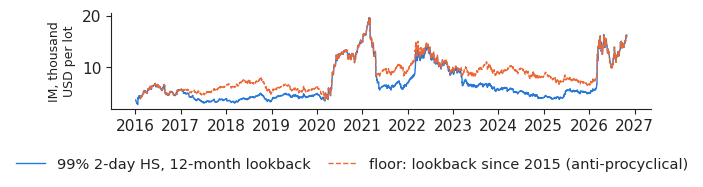

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 1.9))
ax.plot(im.index, im['im1'] / 1000, color=PAL['RO'], lw=1.0, label='99% 2-day HS, 12-month lookback')
ax.plot(im.index, im['ima'] / 1000, color=PAL['DE_LU'], lw=1.0, ls='--', label='floor: lookback since 2015 (anti-procyclical)')
ax.set_ylabel('IM, thousand\nUSD per lot', fontsize=9)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.18, 1, 1))
plt.savefig('brent_im.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()